### TEL351 – Seminario de Telemática I
# Clase 8: Text representation in Graphs
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Datos de tipo texto

El texto es un tipo de dato que, cuando se analiza correctamente, es una fuente de información muy valiosa. Sin embargo, puede ser un desafío explorar datos en forma de texto, especialmente texto sin formato.

<div align="center">
<img src="img/text.png" alt="" width="70%" align="center" />
</div>

# Grafos de texto

A continuación, veremos cómo representar texto plano en un grafo, haciendo que su estructura sea explícita y fácilmente manejable por algoritmos posteriores. Hay varias tareas de procesamiento del lenguaje natural (NLP) que pueden beneficiarse de las representaciones de texto en grafos, como la extracción y el resumen de palabras clave, análisis de sentimientos, etc.



## ¿Cómo crear un grafo de texto?

1. Identificar **entidades** en el texto (palabras, n-gramas, personajes, etc.) para representarlas como nodos en el grafo .
2. Identificar **relaciones** entre esas entidades (co-ocurrencias, significados, sentimientos, etc.) para representarlas como aristas entre nodos. 

Los tipos exactos de entidades y relaciones dependen del contexto y de la tarea.

## Representaciones

Hay 3 formas de representar, a través de un grafo, un documento de texto:

- Usando un grafo no dirigido y no ponderado. 
- Usando un grafo dirigido y no ponderado. 
- Usando un grafo dirigido y ponderado.

## Grafo de Texto del libro Harry Potter y el prisionero de Azkaban

<div align="center">
<img src="img/HP3.jpg" alt="" width="20%" align="center" />
</div>

In [1]:
import networkx as nx
import matplotlib.pyplot as plt
import string

In [2]:
def remove_non_alphanumeric(input_string):
    alphanumeric_string = ''.join(c if c.isalnum() or c.isspace() or c == '\n' else '' for c in input_string)
    return alphanumeric_string

In [3]:
with open("HP3.txt", "r", encoding="utf-8") as f:
    document = f.read()

In [4]:
document = remove_non_alphanumeric(document)

In [5]:
document[:1087]

'JK Rowling\nHarry Potter y el prisionero de Azkaban\n\n\nPor la cicatriz que lleva en la frente sabemos que Harry Potter no es un niño como los demás sino el héroe que venció a lord Voldemort el mago más temible y maligno de todos los tiempos y culpable de la muerte de los padres de Harry Desde entonces Harry no tiene más remedio que vivir con sus pesados tíos y su insoportable primo Dudley todos ellos muggles o sea personas no magas que desprecian a su sobrino debido a sus poderes\nIgual que en las dos primeras partes de la serie La piedra filosofal y La cámara secreta Harry aguarda con impaciencia el inicio del tercer curso en el Colegio Hogwarts de Magia y Hechicería Tras haber cumplido los trece años solo y lejos de sus amigos de Hogwarts Harry se pelea con su bigotuda tía Marge a la que convierte en globo y debe huir en un autobús mágico Mientras tanto de la prisión de Azkaban se ha escapado un terrible villano Sirius Black un asesino en serie con poderes mágicos que fue cómplice

## Preprocesamiento de documentos

La etapa de preprocesamiento debe separar el documento en oraciones y cada oración en palabras. Además, debe normalizar todo el texto en minúsculas y eliminar los signos de puntuación.

In [6]:
def preprocess_document(document, sentence_spliter='.'):
    document = document.lower().strip().translate(str.maketrans('', '', string.punctuation))
    sentences = [sent for sent in document.split(sentence_spliter) if sent != '']
    doc = []
    for sent in sentences:
        words = sent.strip().split()
        doc.append(list(map(str.strip, words)))
    return doc

In [7]:
norm_document = preprocess_document(document)

## Identificar entidades (nodos en el grafo)

En principio, todas las palabras individuales serán nodos en el grafo. Por lo tanto, para cada palabra única en el documento, debe existir un nodo.

In [8]:
def get_entities(document):
    unique_words = []
    for sent in document:
        for word in sent:
            if word not in unique_words:
                unique_words.append(word)
    return unique_words

In [9]:
entities = get_entities(norm_document)

In [10]:
print(entities[:10])

['jk', 'rowling', 'harry', 'potter', 'y', 'el', 'prisionero', 'de', 'azkaban', 'por']


## Identificar relaciones (aristas entre nodos en el grafo)

Existirá una arista entre dos nodos en el grafo si las palabras correspondientes forman un bigrama en una oración del documento de entrada.

In [11]:
def get_relations(document):
    bigrams = []
    for sent in document:
        for i in range(len(sent)-1):
            pair = [sent[i], sent[i+1]]
            if pair not in bigrams:
                bigrams.append(pair)
    return bigrams

In [12]:
relations = get_relations(norm_document)

In [13]:
print(relations[:10])

[['jk', 'rowling'], ['rowling', 'harry'], ['harry', 'potter'], ['potter', 'y'], ['y', 'el'], ['el', 'prisionero'], ['prisionero', 'de'], ['de', 'azkaban'], ['azkaban', 'por'], ['por', 'la']]


## Construyendo el grafo de palabras no dirigido

Ahora que ya se tienen los nodos y aristas, se puede construir el grafo.

In [14]:
def build_graph(document):
    pdoc = preprocess_document(document)
    nodes = get_entities(pdoc)
    edges = get_relations(pdoc)
    G = nx.Graph()
    G.add_nodes_from(nodes)
    G.add_edges_from(edges)
    return G

In [15]:
full_graph = build_graph(document)

In [16]:
print(full_graph)

Graph with 10832 nodes and 53556 edges


In [17]:
degrees = dict(nx.degree(full_graph))

In [18]:
G = full_graph.subgraph([n for n in degrees if degrees[n]>50])

In [19]:
print(G)

Graph with 240 nodes and 6443 edges


In [20]:
def sizes(G, degrees, threshold=200, minsize=10):
    out = []
    for node in G.nodes():
        if degrees[node] <= threshold:
            size = minsize
        else:
            size = 100*degrees[node]**0.5
        out.append(size)
    return out

In [21]:
pos = nx.spring_layout(G, k=3, seed=0)

In [22]:
def plot_text_graph(G, pos, degrees, degree_threshold=200, weight_threshold=10, 
                    title="Grafo de Texto", minsize=10, weighted=False):
    plt.figure(figsize=(20,10))
    s = sizes(G, degrees, degree_threshold, minsize)
    ns = nx.draw_networkx_nodes(G, pos, nodelist=G.nodes, node_size=s, node_color="white")
    ns.set_edgecolor('#707070')
    nx.draw_networkx_labels(G,pos,{n:n for n in G.nodes() if degrees[n]>degree_threshold},font_size=10)
    
    if weighted:
        for e in G.edges(data=True):
            if e[2]['weight']>weight_threshold:
                nx.draw_networkx_edges(G,pos,[e],width=e[2]['weight']/100,edge_color='#707070')
    else:
        nx.draw_networkx_edges(G,pos,G.edges,edge_color='#707070')
    plt.title(title,fontsize = 24)
    plt.axis('off')
    plt.show()

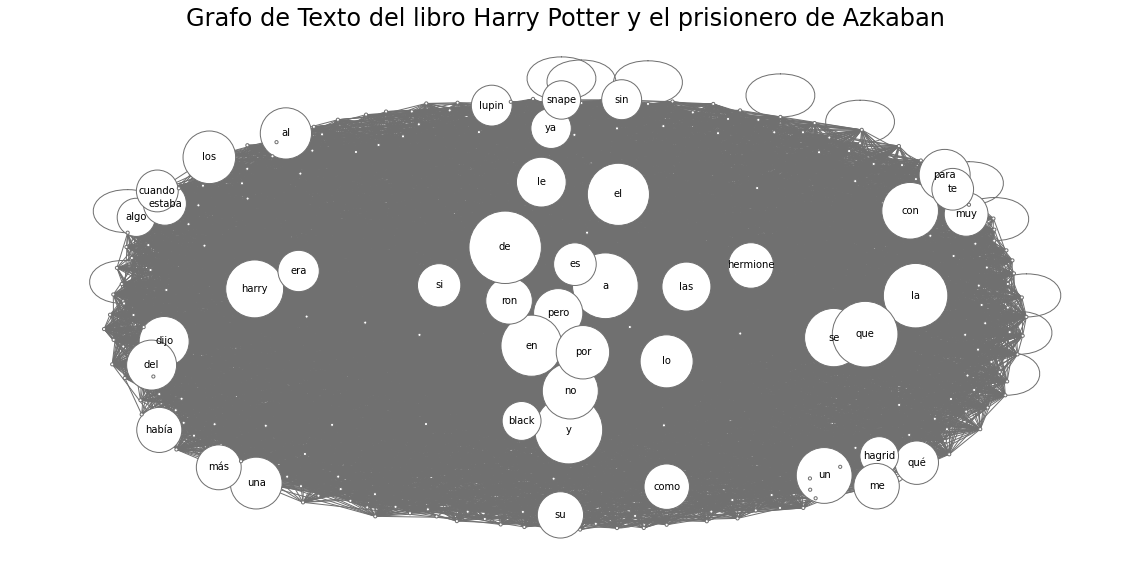

In [23]:
plot_text_graph(G, pos, degrees, title="Grafo de Texto del libro Harry Potter y el prisionero de Azkaban")

## Grafo dirigido y ponderado

Ponderaremos cada arista según el número de veces que aparece el bigrama correspondiente en el documento.

In [24]:
def get_weighted_edges(document):
    bigrams = {}
    for sent in document:
        for i in range(len(sent)-1):
            pair = str([sent[i], sent[i+1]])
            if pair not in bigrams.keys():
                bigrams[pair] = 1
            else:
                bigrams[pair] += 1
    weighted_edges_format = []
    for pair, weight in bigrams.items():
        w1, w2 = eval(pair)
        weighted_edges_format.append([w1, w2, weight])
    return weighted_edges_format

In [25]:
weighted_relations = get_weighted_edges(norm_document)

In [26]:
print(weighted_relations[:10])

[['jk', 'rowling', 2], ['rowling', 'harry', 1], ['harry', 'potter', 23], ['potter', 'y', 4], ['y', 'el', 75], ['el', 'prisionero', 1], ['prisionero', 'de', 1], ['de', 'azkaban', 20], ['azkaban', 'por', 1], ['por', 'la', 126]]


## Construyendo un grafo de palabras dirigido y ponderado

In [27]:
def build_weighted_digraph(document):
    pdoc = preprocess_document(document)
    nodes = get_entities(pdoc)
    weighted_edges = get_weighted_edges(pdoc)
    G = nx.DiGraph()
    G.add_nodes_from(nodes)
    G.add_weighted_edges_from(weighted_edges)
    return G 

In [28]:
full_weight_graph = build_weighted_digraph(document)

In [29]:
WG = full_weight_graph.subgraph([n for n in G.nodes])

In [30]:
print(WG)

DiGraph with 240 nodes and 7344 edges


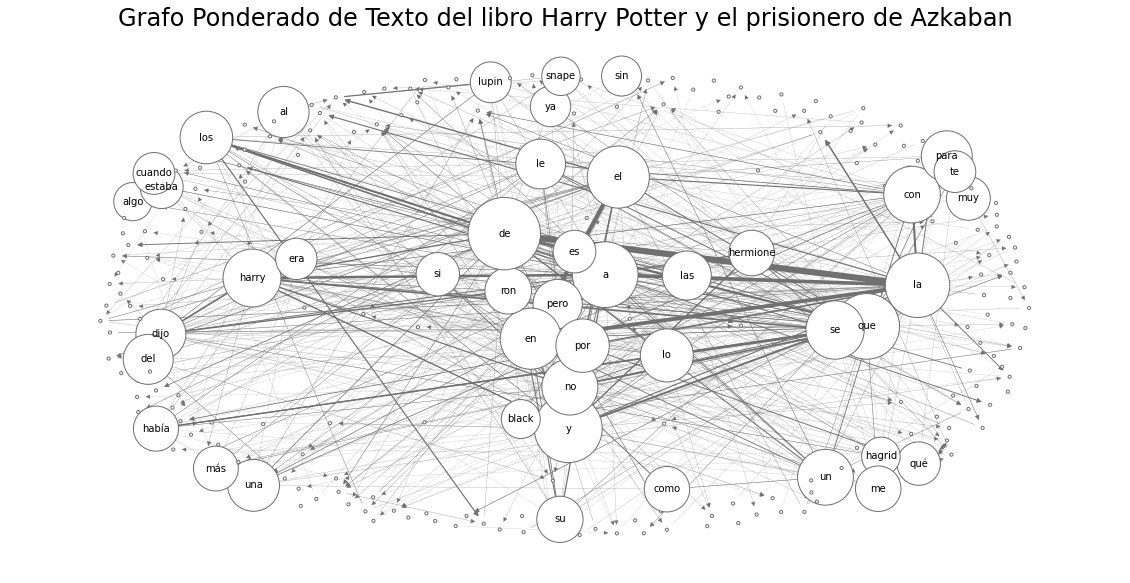

In [31]:
plot_text_graph(WG, pos, degrees, title="Grafo Ponderado de Texto del libro Harry Potter y el prisionero de Azkaban", weighted=True)

# Y ahora qué?

Muy bien, ahora que tengo un grafo... ¿de qué me sirve?, ¿qué puedo hacer con él?

## Calificación de los nodos en el grafo

Cada nodo del grafo representa un término presente en el documento de entrada (un solo nodo para los múltiples usos del mismo término). Podemos usar cualquier medida de centralidad para calificar nodos en el grafo.

In [32]:
node_scores = nx.betweenness_centrality(WG)

In [33]:
print(list(node_scores.items())[:15])

[('vez', 0.002492314890164161), ('weasley', 0.0014440663257464514), ('seguía', 0.00034266739961874364), ('unos', 0.001558804386115181), ('ya', 0.00553251073215027), ('sirius', 0.0020377761199153795), ('oído', 0.006405800057300767), ('estar', 0.0012995949090793154), ('había', 0.008458305781787497), ('algo', 0.004711175247547386), ('susurró', 0.000787632765293575), ('son', 0.00016155148076298), ('grande', 0.00037074697642716566), ('gryffindor', 0.0008798163857594126), ('al', 0.005704767300734586)]


## Extraer palabras clave

Simplemente definimos como palabras clave candidatas los nodos de mayor puntuación. La cantidad exacta de nodos que desea considerar como palabras clave candidatas depende de su tarea.

In [34]:
sorted_node_scores = dict(sorted(node_scores.items(), key=lambda item: -item[1]))

In [35]:
candidate_kw = list(sorted_node_scores.keys())

In [36]:
print(candidate_kw[:15])

['que', 'de', 'y', 'harry', 'a', 'no', 'la', 'en', 'con', 'dijo', 'lo', 'pero', 'el', 'por', 'ron']


## Extraer frases clave

Una frase clave es una frase relevante en el documento de entrada, que se puede utilizar para varias tareas, como el resumen extractivo, indexación, respuesta a consultas, etc. Definiremos una frase clave como una secuencia de palabras en el documento de entrada compuesta únicamente por palabras clave candidatas.

In [37]:
#!pip install spacy

In [38]:
import spacy

In [39]:
import nltk

In [40]:
from spacy.tokens import Token

In [41]:
#!python -m spacy download es_core_news_sm

In [42]:
nlp = spacy.load("es_core_news_sm")

In [43]:
def transform_uni_to_ngram(unigram_keywords, text):
    ckw_getter = lambda token: token.text.lower() in unigram_keywords
    Token.set_extension("is_ckw", getter=ckw_getter, force=True)
    res = []
    sentences = nltk.sent_tokenize(text)
    for sent in sentences:
        merged_tokens = ''
        sent = nlp(sent)
        for token in sent:
            if token._.is_ckw:
                merged_tokens += token.text.lower() + ' '
            else:              
                if merged_tokens != '' and merged_tokens.strip() not in res:
                    if len(merged_tokens.strip().split(' ')) != 1:
                        res.append(merged_tokens.strip())
                    merged_tokens = ''
    for uni in unigram_keywords:
        if uni not in res:
            add_uni = True
            for other in res:          
                if uni in other:
                    add_uni = False
            if add_uni:
                res.append(uni)   
    return res

In [44]:
keyphrases = transform_uni_to_ngram(candidate_kw, document)

In [45]:
print(keyphrases[:20])

['harry potter y el', 'por la', 'en la', 'que harry potter no es un', 'como los', 'de todos los', 'de la', 'de los', 'de harry desde entonces harry no tiene más', 'con sus', 'y su', 'todos ellos', 'a su', 'a sus', 'que en las dos', 'de la la', 'y la', 'en el colegio hogwarts de', 'tras haber', 'de sus']


In [46]:
def colourise(colour, text):
    if colour == "black":
        return "\033[1;30m" + str(text) + "\033[1;m"
    if colour == "red":
        return "\033[1;31m" + str(text) + "\033[1;m"
    if colour == "green":
        return "\033[1;32m" + str(text) + "\033[1;m"
    if colour == "yellow":
        return "\033[1;33m" + str(text) + "\033[1;m"
    if colour == "blue":
        return "\033[1;34m" + str(text) + "\033[1;m"
    if colour == "magenta":
        return "\033[1;35m" + str(text) + "\033[1;m"
    if colour == "cyan":
        return "\033[1;36m" + str(text) + "\033[1;m"
    if colour == "gray":
        return "\033[1;37m" + str(text) + "\033[1;m"
    return str(text)

In [47]:
def highlight(document, keyphrases):
    doc = document.split()
    for key in keyphrases:
        k = key.split()
        i = 0
        while i < (len(doc) - len(k)):            
            d = []
            for x in doc[i:len(k)+i]:
                 d.append(x.lower().strip().translate(str.maketrans('', '', string.punctuation)))
            if d == k:              
                res = []
                for w in doc[i:len(k)+i]:
                    res.append(colourise('red', w))
                doc[i:len(k)+i] = res
            i += 1
    print(" ".join(doc))

In [48]:
highlight(document[:1087], keyphrases)

JK Rowling Harry Potter y el prisionero de Azkaban Por la cicatriz que lleva en la frente sabemos que Harry Potter no es un niño como los demás sino el héroe que venció a lord Voldemort el mago más temible y maligno de todos los tiempos y culpable de la muerte de los padres de Harry Desde entonces Harry no tiene más remedio que vivir con sus pesados tíos y su insoportable primo Dudley todos ellos muggles o sea personas no magas que desprecian a su sobrino debido a sus poderes Igual que en las dos primeras partes de la serie La piedra filosofal y La cámara secreta Harry aguarda con impaciencia el inicio del tercer curso en el Colegio Hogwarts de Magia y Hechicería Tras haber cumplido los trece años solo y lejos de sus amigos de Hogwarts Harry se pelea con su bigotuda tía Marge a la que convierte en globo y debe huir en un autobús mágico Mientras tanto de la prisión de Azkaban se ha escapado un terrible villano Sirius Black un asesino en serie con poderes mágicos que fue cómplice de lord

## Named-entity recognition (NER)

**Localiza** y **clasifica** la entidad mencionada en texto, dentro de categorías pre-definidas como nombres de personas, organizaciones, ubicaciones, códigos médicos, expresiones de tiempo, cantidades, valores monetarios, etc.

In [49]:
from spacy import displacy

In [50]:
displacy.render(nlp(document[:1087]), style="ent", jupyter=True)

# Character Network

Modela las relaciones entre personajes de un documento.

In [51]:
from collections import Counter

In [52]:
doc = nlp(document)
entity_counter = Counter()
for entity in doc.ents:
    if entity.label_ == "PER":
        entity_counter[entity.text] += 1

In [53]:
top_characters = [entity for entity, count in entity_counter.most_common(10)]
top_characters

['Ron',
 'Hermione',
 'Lupin',
 'Hagrid',
 'Snape',
 'Dumbledore',
 'Sirius',
 'Buckbeak',
 'Pettigrew',
 'Fred']

In [54]:
graph = nx.Graph()

In [55]:
for character in top_characters:
    graph.add_node(character, frequency=entity_counter[character])

In [56]:
# !pip install pysentimiento

In [57]:
# !pip install transformers[torch]

In [58]:
from pysentimiento import create_analyzer

In [59]:
sentiment_analyzer = create_analyzer(task="sentiment", lang="es")

In [60]:
for i, token in enumerate(doc):
    if token.text in top_characters:
        for j in range(i - 5, i + 6):
            if j >= 0 and j < len(doc) and j != i and doc[j].text in top_characters:
                source = token.text
                target = doc[j].text
                if not graph.has_edge(source, target):
                    graph.add_edge(source, target, weight=0, sentiment=0)
                graph[source][target]['weight'] += 1
                sentiment = sentiment_analyzer.predict(document[i:j+1])
                if sentiment.output == "POS":
                    graph[source][target]['sentiment'] += 1
                elif sentiment.output == "NEG":
                    graph[source][target]['sentiment'] -= 1

In [61]:
def normalize_list(values):
    new_values = sorted(values, reverse=True)
    min_val = new_values[-1]
    max_val = new_values[1]
    range_val = max_val - min_val
    normalized_values = [(x - min_val) / range_val for x in new_values[1:]]
    normalized_values.insert(0,1.0)
    return normalized_values

In [62]:
node_sizes = [data['frequency'] * 10 for _, data in graph.nodes(data=True)]
edge_weights = [data['weight']/20 for _, _, data in graph.edges(data=True)]
edge_sentiments = [data['sentiment'] for _, _, data in graph.edges(data=True)]
edge_polarity = normalize_list(edge_sentiments)
pos = nx.spring_layout(graph, k=10, seed=42)

In [63]:
def plot_sentiment_graph(graph, pos, node_sizes, edge_weights, node_color='white', 
                         edgecolors='#707070', edge_colors='k', edge_cmap=plt.cm.bwr_r, title=""):
    plt.figure(figsize=(10, 10))
    ax = plt.gca()
    nx.draw_networkx_nodes(graph, pos, node_color=node_color, edgecolors=edgecolors, node_size=node_sizes, ax=ax)
    nx.draw_networkx_edges(graph, pos, width=edge_weights, edge_color=edge_colors, edge_cmap=edge_cmap, ax=ax)
    nx.draw_networkx_labels(graph, pos, font_size=10, font_color="black", ax=ax)
    plt.axis('off')
    plt.title(title)
    plt.show()

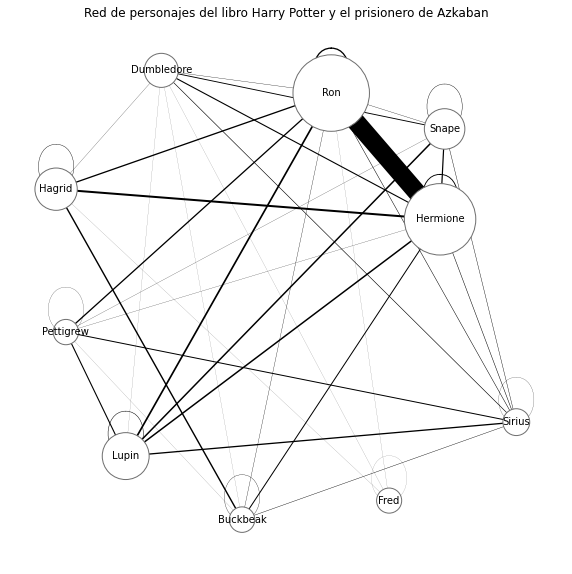

In [64]:
plot_sentiment_graph(graph, pos, node_sizes, edge_weights, title='Red de personajes del libro Harry Potter y el prisionero de Azkaban')

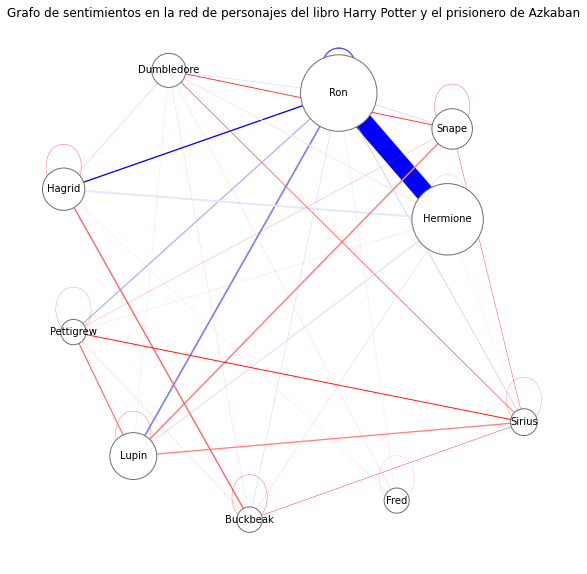

In [65]:
plot_sentiment_graph(graph, pos, node_sizes, edge_weights, edge_colors=edge_polarity, title="Grafo de sentimientos en la red de personajes del libro Harry Potter y el prisionero de Azkaban")